In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/houses_clean.csv")

df["log_price"] = np.log(df["price"])
df["log_area"] = np.log(df["area_marla"])
df["loc_key"] = df["city"] + " | " + df["location"]

print(df.shape)
df.head()

(66158, 12)


,price,area_marla,bedrooms,baths,city,location,latitude,longitude,date_added,log_price,log_area,loc_key
0,16500000,8.0,5,6,Islamabad,G-15,33.631486,72.926559,07-17-2019,16.618871,2.079442,Islamabad | G-15
1,43500000,40.0,4,4,Islamabad,Bani Gala,33.707573,73.151199,04-05-2019,17.588271,3.688879,Islamabad | Bani Gala
2,7000000,8.0,3,3,Islamabad,DHA Defence,33.492591,73.301339,07-10-2019,15.761421,2.079442,Islamabad | DHA Defence
3,34500000,32.0,8,8,Islamabad,Ghauri Town,33.623947,73.126588,04-05-2019,17.356470,3.465736,Islamabad | Ghauri Town
4,27000000,20.0,8,8,Islamabad,Korang Town,33.579034,73.139591,01-04-2019,17.111347,2.995732,Islamabad | Korang Town


In [2]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, random_state=42)
print("Train:", len(train), " Test:", len(test))

Train: 52926  Test: 13232


In [3]:
def evaluate(name, y_true_log, y_pred_log):
    true = np.exp(y_true_log)
    pred = np.exp(y_pred_log)
    pct_err = np.abs(pred - true) / true
    print(f"{name:22s} | median error: {np.median(pct_err)*100:5.1f}% "
          f"| within 20%: {(pct_err <= 0.2).mean()*100:5.1f}% "
          f"| MAE: {np.mean(np.abs(pred - true))/1e6:6.2f}M PKR")

In [4]:
city_ppm = (train["price"] / train["area_marla"]).groupby(train["city"]).median()
pred = np.log(test["city"].map(city_ppm) * test["area_marla"])

evaluate("Baseline (city × area)", test["log_price"], pred)

Baseline (city × area) | median error:  23.6% | within 20%:  44.3% | MAE:   9.35M PKR


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

lin_feats = ["city", "log_area", "bedrooms", "baths"]

lin = Pipeline([
    ("prep", ColumnTransformer(
        [("city", OneHotEncoder(handle_unknown="ignore"), ["city"])],
        remainder="passthrough")),
    ("model", LinearRegression()),
])

lin.fit(train[lin_feats], train["log_price"])
evaluate("Linear regression", test["log_price"], lin.predict(test[lin_feats]))

Linear regression      | median error:  23.4% | within 20%:  43.3% | MAE:   8.69M PKR


In [6]:
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import HistGradientBoostingRegressor

gb_feats = ["city", "loc_key", "log_area", "bedrooms", "baths", "latitude", "longitude"]

gbm = Pipeline([
    ("prep", ColumnTransformer([
        ("city", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["city"]),
        ("loc", TargetEncoder(target_type="continuous", random_state=42), ["loc_key"]),
    ], remainder="passthrough")),
    ("model", HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.05, random_state=42)),
])

gbm.fit(train[gb_feats], train["log_price"])
evaluate("Gradient boosting", test["log_price"], gbm.predict(test[gb_feats]))

c:\Users\LENOVO\Documents\zameen-price-predictor\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Gradient boosting      | median error:  10.3% | within 20%:  76.0% | MAE:   4.43M PKR


## Model comparison (test set, 13,232 houses)

| Model | Features | Median error | Within ±20% | MAE (PKR) |
|---|---|---|---|---|
| Baseline (city price/Marla × area) | city, area | 23.6% | 44.3% | 9.35M |
| Linear regression | city, area, bedrooms, baths | 23.4% | 43.3% | 8.69M |
| **Gradient boosting** | + location, latitude/longitude | **10.5%** | **76.0%** | **4.43M** |

**Key findings**
- Bedrooms and baths add almost nothing beyond area: linear regression barely beats the simple baseline.
- Location is the biggest driver of price: adding it cut the typical error by more than half (23.5% → 10.5%).
- The final model predicts 3 out of 4 houses within ±20% of their listed price.


In [7]:
test = test.copy()
test["pred_price"] = np.exp(gbm.predict(test[gb_feats]))
test["pct_err"] = (test["pred_price"] - test["price"]).abs() / test["price"]
test["signed_err"] = (test["pred_price"] - test["price"]) / test["price"]
test[["city", "location", "area_marla", "price", "pred_price", "pct_err"]].head()

,city,location,area_marla,price,pred_price,pct_err
48434,Rawalpindi,Bahria Town Rawalpindi,10.0,26000000,2.323294e+07,0.106425
14957,Rawalpindi,Satellite Town,7.0,38000000,2.926144e+07,0.229962
23699,Karachi,DHA Defence,40.0,185000000,1.935306e+08,0.046111
17095,Lahore,State Life Housing Society,10.0,23000000,2.093972e+07,0.089578
36279,Karachi,Cantt,14.0,51000000,5.710670e+07,0.119739


In [8]:
test.groupby("city").agg(
    houses=("price", "size"),
    median_error=("pct_err", "median"),
    within_20=("pct_err", lambda x: (x <= 0.2).mean()),
).round(3)

,houses,median_error,within_20
city,,,
Faisalabad,335,0.169,0.591
Islamabad,1770,0.095,0.802
Karachi,3177,0.102,0.735
Lahore,6482,0.103,0.775
Rawalpindi,1468,0.106,0.739


In [9]:
test["price_band"] = pd.qcut(test["price"], 5,
    labels=["Cheapest 20%", "Low", "Middle", "High", "Top 20%"])

test.groupby("price_band", observed=True).agg(
    median_error=("pct_err", "median"),
    bias=("signed_err", "median"),
).round(3)

,median_error,bias
price_band,,
Cheapest 20%,0.126,0.051
Low,0.086,0.001
Middle,0.085,-0.012
High,0.107,-0.033
Top 20%,0.117,-0.043


In [17]:
from pathlib import Path
Path("../images").mkdir(exist_ok=True)

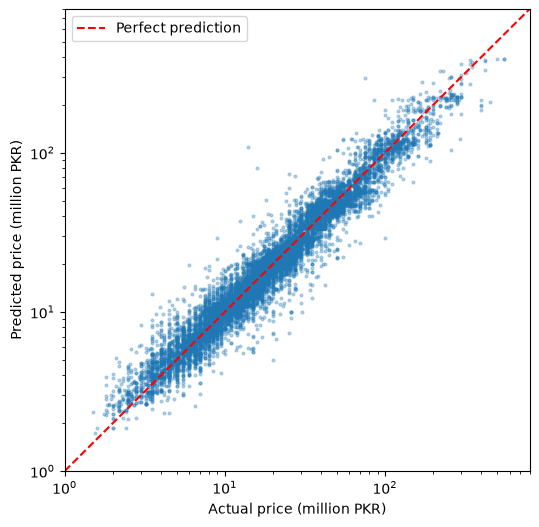

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test["price"] / 1e6, test["pred_price"] / 1e6, s=4, alpha=0.3)
lims = [1, 800]
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual price (million PKR)"); ax.set_ylabel("Predicted price (million PKR)")
ax.legend();
plt.savefig("../images/pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

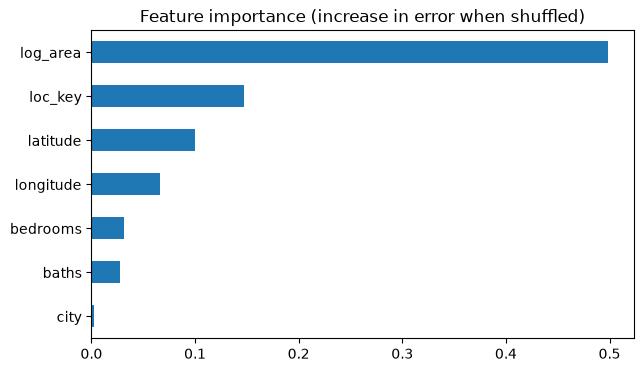

In [21]:
from sklearn.inspection import permutation_importance

sample = test.sample(5000, random_state=1)
r = permutation_importance(gbm, sample[gb_feats], sample["log_price"],
                           n_repeats=5, random_state=42,
                           scoring="neg_mean_absolute_error")

imp = pd.Series(r.importances_mean, index=gb_feats).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Feature importance (increase in error when shuffled)")
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
test.sort_values("pct_err", ascending=False)[
    ["city", "location", "area_marla", "bedrooms", "baths", "price", "pred_price", "pct_err"]
].head(10)

,city,location,area_marla,bedrooms,baths,price,pred_price,pct_err
66092,Islamabad,F-7,20.0,7,7,14000000,1.090879e+08,6.791992
28977,Karachi,DHA Defence,20.0,3,3,16000000,8.074240e+07,4.046400
62513,Islamabad,Naval Farms Housing Scheme,100.0,6,7,75000000,2.945483e+08,2.927311
55574,Islamabad,G-15,5.0,3,3,3500000,1.292412e+07,2.692606
9057,Karachi,Gulistan-e-Jauhar,6.0,5,6,6000000,1.978313e+07,2.297188
14168,Karachi,Gulshan-e-Iqbal Town,4.8,6,6,9000000,2.911531e+07,2.235035
48081,Karachi,Gulistan-e-Jauhar,12.0,4,4,12500000,3.730928e+07,1.984742
19898,Karachi,Malir,22.0,7,7,25000000,7.320320e+07,1.928128
54287,Lahore,DHA Defence,20.0,5,5,18000000,5.051024e+07,1.806124
21104,Karachi,Gulistan-e-Jauhar,3.0,3,3,3000000,8.311428e+06,1.770476


In [13]:
import joblib
from pathlib import Path
from sklearn.base import clone

final_model = clone(gbm).fit(df[gb_feats], df["log_price"])

Path("../models").mkdir(exist_ok=True)
joblib.dump(final_model, "../models/price_model.joblib")

locs = (df.groupby(["city", "location"])
          .agg(latitude=("latitude", "median"),
               longitude=("longitude", "median"),
               listings=("price", "size"))
          .reset_index())
locs.to_csv("../models/locations.csv", index=False)

print("Saved model and", len(locs), "locations")

c:\Users\LENOVO\Documents\zameen-price-predictor\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Saved model and 1365 locations


In [14]:
model = joblib.load("../models/price_model.joblib")
locs = pd.read_csv("../models/locations.csv")

def predict_price(city, location, area_marla, bedrooms, baths):
    row = locs[(locs["city"] == city) & (locs["location"] == location)].iloc[0]
    X = pd.DataFrame([{
        "city": city,
        "loc_key": f"{city} | {location}",
        "log_area": np.log(area_marla),
        "bedrooms": bedrooms,
        "baths": baths,
        "latitude": row["latitude"],
        "longitude": row["longitude"],
    }])[gb_feats]
    return float(np.exp(model.predict(X)[0]))

p = predict_price("Lahore", "DHA Defence", 10, 4, 4)
print(f"Predicted price: {p/1e7:.2f} crore PKR")

Predicted price: 2.97 crore PKR


## Error analysis

**By city:** Islamabad performs best (9.6% median error). Karachi, Lahore and Rawalpindi sit around 10–11%. Faisalabad is weakest (13.8%) because it has the fewest listings to learn from.

**By price range:** the model is most accurate for mid-market houses (~9% error, no bias). It slightly overprices the cheapest 20% (+5%) and underprices the most expensive 40% (−4%), a common "regression to the mean" effect.

**Feature importance:** area is the strongest driver, followed by location (location name + coordinates together are close to area). City shows near-zero importance only because location and coordinates already identify the city. Bedrooms and baths add little once size is known.

**Limitations:** the data covers 2018–2019 listings (asking prices, not sale prices), and it lacks plot features such as corner, main road or park-facing.
